<a href="https://colab.research.google.com/github/dibyajit-saha/CLustering-of-Murder_crimes-dataset/blob/main/Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

from sklearn.metrics import accuracy_score

In [2]:
url = "https://raw.githubusercontent.com/dibyajit-saha/CLustering-of-Murder_crimes-dataset/refs/heads/main/crime_data.csv"
data = pd.read_csv(url)
data.head(3) #first column name is not proper

,Unnamed: 0,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0


In [3]:
data.rename(columns = {'Unnamed: 0' : 'States'},inplace = True)
data.head(3) #changed the first  column name to states

,States,Murder,Assault,UrbanPop,Rape
0,Alabama,13.2,236,58,21.2
1,Alaska,10.0,263,48,44.5
2,Arizona,8.1,294,80,31.0


In [4]:
data.isnull().sum() # checked null values

,0
States,0
Murder,0
Assault,0
UrbanPop,0
Rape,0


In [5]:
data.dtypes #checked datatypes

,0
States,object
Murder,float64
Assault,int64
UrbanPop,int64
Rape,float64


In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

In [7]:
columns = data.columns
print (columns) # all columns in a list

Index(['States', 'Murder', 'Assault', 'UrbanPop', 'Rape'], dtype='object')


In [8]:
def check_outliers(data, column):
    sns.boxplot(x=data[column])
    plt.show() # function for checking outliers in boxplot

Column Name:  Murder


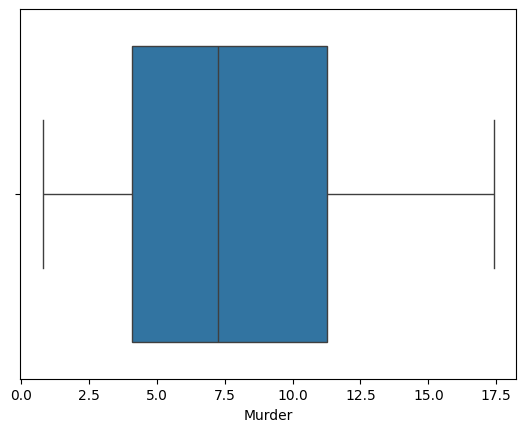

Column Name:  Assault


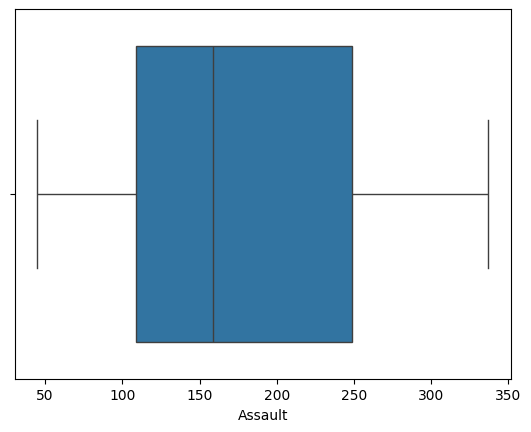

Column Name:  UrbanPop


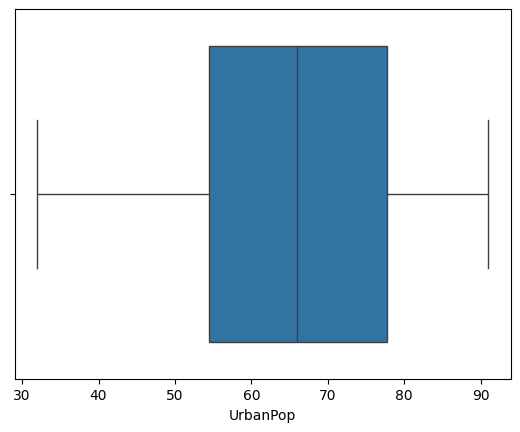

Column Name:  Rape


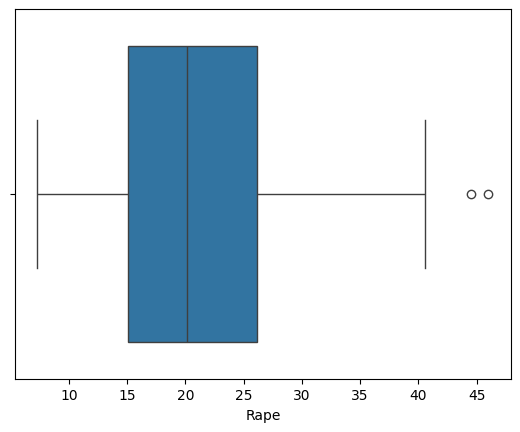

In [9]:
num_cols = data.select_dtypes(include='number')
for i in num_cols:
    print ("Column Name: ", i)
    check_outliers(data,i) # inference = no outliers

In [27]:
data.shape

(50, 5)

In [12]:
from scipy.cluster.hierarchy import linkage
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

In [15]:
X = data.columns.drop ('States')
X = data[X]
X_scaled = StandardScaler().fit_transform(X)
X_scaled

array([[ 1.25517927,  0.79078716, -0.52619514, -0.00345116],
       [ 0.51301858,  1.11805959, -1.22406668,  2.50942392],
       [ 0.07236067,  1.49381682,  1.00912225,  1.05346626],
       [ 0.23470832,  0.23321191, -1.08449238, -0.18679398],
       [ 0.28109336,  1.2756352 ,  1.77678094,  2.08881393],
       [ 0.02597562,  0.40290872,  0.86954794,  1.88390137],
       [-1.04088037, -0.73648418,  0.79976079, -1.09272319],
       [-0.43787481,  0.81502956,  0.45082502, -0.58583422],
       [ 1.76541475,  1.99078607,  1.00912225,  1.1505301 ],
       [ 2.22926518,  0.48775713, -0.38662083,  0.49265293],
       [-0.57702994, -1.51224105,  1.21848371, -0.11129987],
       [-1.20322802, -0.61527217, -0.80534376, -0.75839217],
       [ 0.60578867,  0.94836277,  1.21848371,  0.29852525],
       [-0.13637203, -0.70012057, -0.03768506, -0.0250209 ],
       [-1.29599811, -1.39102904, -0.5959823 , -1.07115345],
       [-0.41468229, -0.67587817,  0.03210209, -0.34856705],
       [ 0.44344101, -0.

In [19]:
km = KMeans(n_clusters=5)
km.fit (X_scaled)
pred = km.predict (X_scaled)

In [20]:
data['KMeans'] = pred
data.head(3)

,States,Murder,Assault,UrbanPop,Rape,KMeans
0,Alabama,13.2,236,58,21.2,1
1,Alaska,10.0,263,48,44.5,1
2,Arizona,8.1,294,80,31.0,1


<Axes: xlabel='States', ylabel='Murder'>

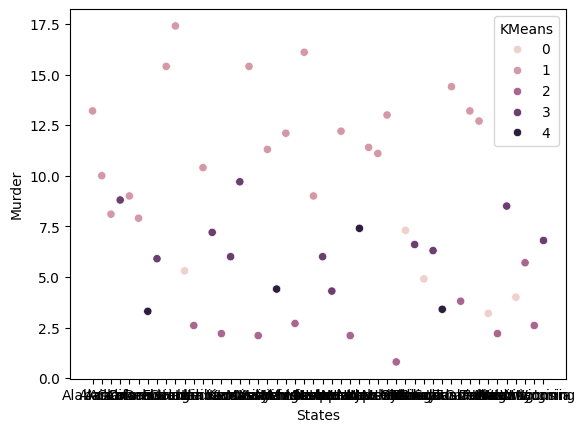

In [22]:
sns.scatterplot(x = 'States', y = 'Murder', data = data, hue = 'KMeans' )

<Axes: xlabel='States', ylabel='Assault'>

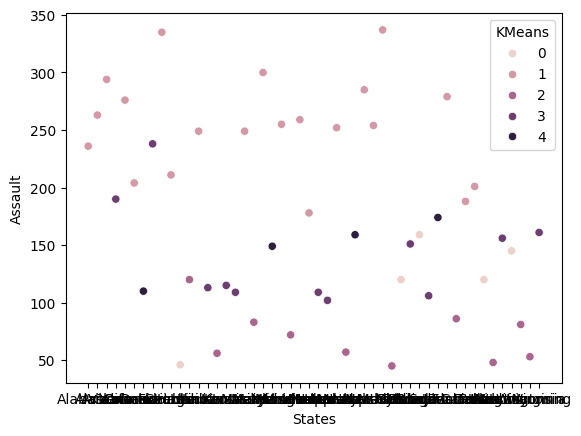

In [23]:
sns.scatterplot(x = 'States', y = 'Assault', data = data, hue = 'KMeans' )

<Axes: xlabel='States', ylabel='UrbanPop'>

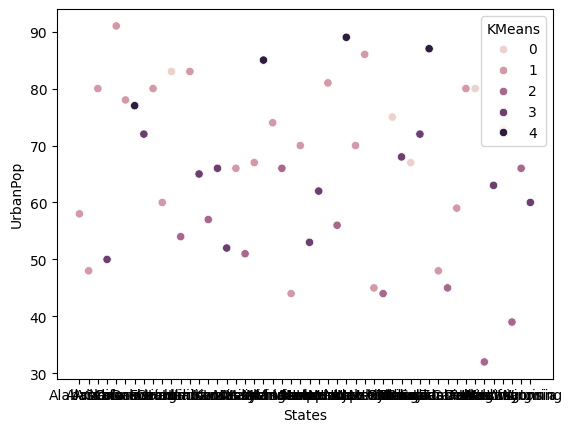

In [24]:
sns.scatterplot(x = 'States', y = 'UrbanPop', data = data, hue = 'KMeans' )

<Axes: xlabel='States', ylabel='Rape'>

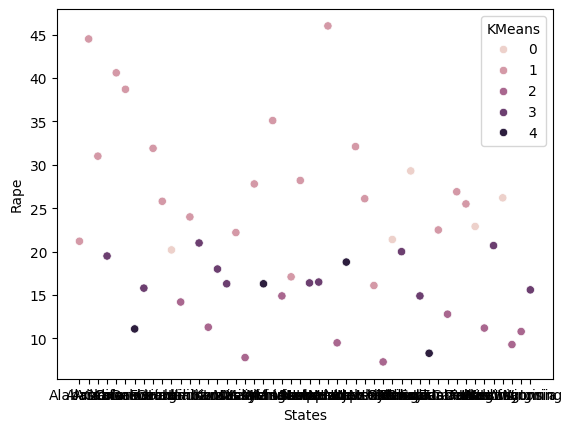

In [25]:
sns.scatterplot(x = 'States', y = 'Rape', data = data, hue = 'KMeans' )

In [26]:
from math import sqrt
sqrt(len(data)/2)

5.0

In [27]:
wcss = []
k = range(1,11)
for i in k:
  km = KMeans(n_clusters=i)
  km.fit(X)
  wcss.append(km.inertia_)
print(wcss)

[355807.82159999997, 96399.02814449919, 47964.265357142845, 37036.80255742296, 33349.32948412698, 20908.78617948718, 15910.129416666674, 15901.040666666664, 13500.48441666667, 10947.044500000004]


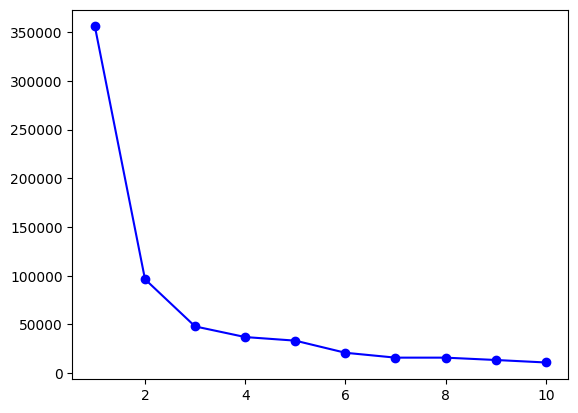

In [28]:
plt.plot(k,wcss,'bo-' )

In [29]:
score = silhouette_score(X,pred) ### More towards 1 the more better it is
print(score)

0.21140861937880487


In [36]:
km = KMeans(n_clusters=3)
km.fit (X_scaled)
pred3 = km.predict (X_scaled)

In [37]:
score = silhouette_score(X,pred3) ### More towards 1 the more better it is
print(score)

0.34742427834883016


In [45]:
data['KM3'] = pred3

Column name:  Murder


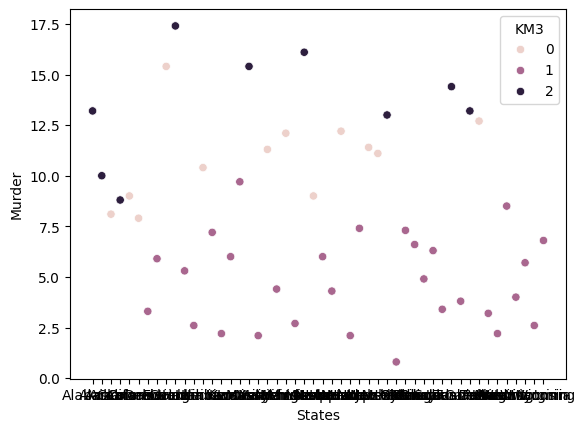

Column name:  Assault


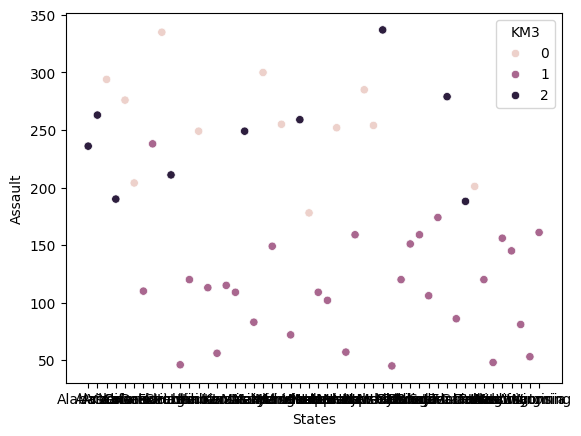

Column name:  UrbanPop


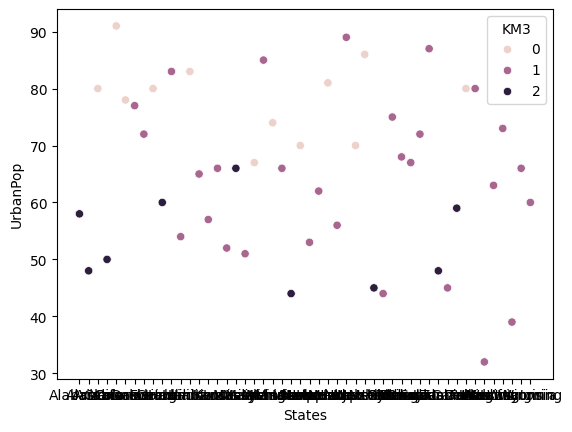

Column name:  Rape


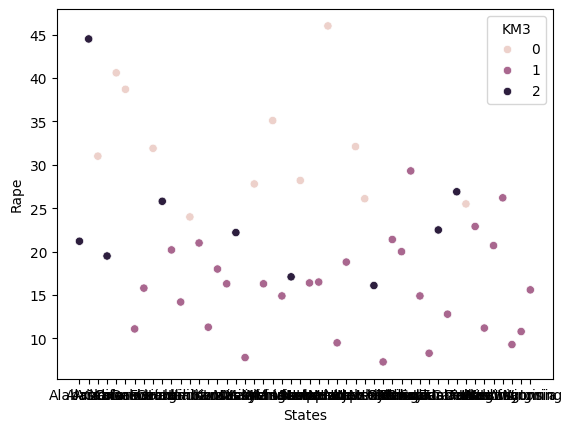

In [46]:
for i in X:
  print ('Column name: ',i)
  sns.scatterplot(x = 'States', y = i, data = data, hue = 'KM3' )
  plt.show()

In [52]:
## Agglo

agg = AgglomerativeClustering(n_clusters=3,linkage = 'ward')
pred_agg = agg.fit_predict(X_scaled)
ss = silhouette_score(X,pred_agg)
print(ss)

0.37577145261338957


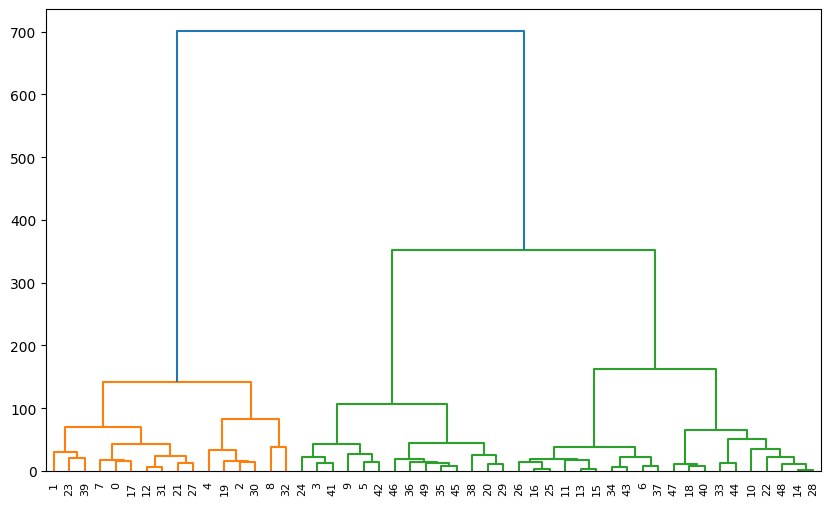

In [48]:
Z = linkage(X, method='ward')
plt.figure(figsize=(10,6))
dendrogram(Z)
plt.show()